In [1]:
from qiskit import __version__
import numpy as np
from numpy import sqrt
from qiskit.visualization import array_to_latex, plot_histogram
from IPython.display import display
from qiskit.quantum_info import Statevector, Operator
from qiskit import QuantumCircuit

In [2]:
print(__version__)

2.6.2


In [3]:
ket0 = np.array([[1],[0]])
ket1 = np.array([[0],[1]])
display(array_to_latex(ket0/2 + ket1/2))


<IPython.core.display.Latex object>

In [4]:
M1 = np.array([
    [1,1],
    [0,0]
])

M2 = np.array([
    [1,0],
    [0,1]
])

M = M1 / 2 + M2 / 2
display(array_to_latex(M))

<IPython.core.display.Latex object>

### Matrix multiplication, including matrix-vector multiplication as a special case, can be performed using the @ operator


In [5]:
display(array_to_latex(M1 @ ket1))
display(array_to_latex(M1 @ ket0))
display(array_to_latex(M @ M))

display(array_to_latex(M1 @ ket0))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

### States, measurements, and operations
#### TheStatevector class in Qiskit provides functionality for defining and manipulating quantum state vectors.


In [6]:
u = Statevector([1 / sqrt(2), 1 / sqrt(2)])
v = Statevector([(1 + 2.0j) / 3, -2 / 3])
w = Statevector([1 / 3, 2 / 3])

#### The Statevector class includes a draw method for displaying state vectors in a variety of ways, including text for plain text, latex for rendered LaTeX, and latex_source for LaTeX code, which can be handy for cutting and pasting into documents.


In [7]:
display(u.draw("text"))
display(v.draw("latex"))
display(w.draw("latex_source"))


[0.70710678+0.j,0.70710678+0.j]

<IPython.core.display.Latex object>

'\\frac{1}{3} |0\\rangle+\\frac{2}{3} |1\\rangle'

In [8]:
# The StateVector class also includes the  `is_valid` method, which allows us to check if the given vector is a valid quantum state vector i.e. its euclidian norm is 1.
print(u.is_valid())
print(v.is_valid())
print(w.is_valid())

True
True
False


In [9]:
display(v.draw("latex"))

<IPython.core.display.Latex object>

#### Simulating measurements using Statevector
##### Running the measure method simulates a standard basis measurement. It returns the outcome of that measurement, plus the new quantum state vector of the system after the measurement. 

In [10]:
outcome, state = v.measure()
print(f"Measured: {outcome} \n Post-measurement state:")
display(state.draw("latex"))
#Measurement outcomes are probabilistic, so this method can return different results when run multiple times.

Measured: 0 
 Post-measurement state:


<IPython.core.display.Latex object>

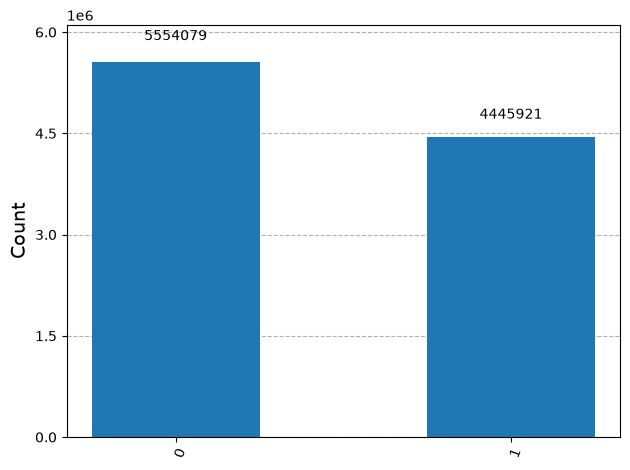

In [11]:
#Statevector will throw an error if the measure method is applied to an invalid quantum state vector.
#Statevector also comes with a sample_counts method that allows for the simulation of any number of measurements on the system, each time starting with a fresh copy of the state.
statistics = v.sample_counts(10000000)
plot_histogram(statistics)
#With more and more samples, the fraction of samples for each possibility is likely to get closer and closer to the corresponding probability. This phenomenon, more generally speaking, is known as the law of large numbers in probability theory.

### Perform operations with Operator and Statevector
#### Unitary operations can be defined in Qiskit using the Operator class, as in the example that follows. This class includes a draw method with similar arguments to Statevector. Note that the latex option produces results equivalent to array_to_latex.

In [12]:
Y = Operator([[0, -1.0j], [1.0j, 0]])
H = Operator([[1/sqrt(2), 1/sqrt(2)]
              ,[1/sqrt(2),-1/sqrt(2)]])
S = Operator([[1,0],[0,1.0j]])
T = Operator([[1,0],
              [0,(1+1.0j)/sqrt(2)]])


In [13]:
#We can apply a unitary operation to a state vector using the evolve method.
v = Statevector([[1],[0]])
display(v.draw("latex"))

v = v.evolve(H)
display(v.draw("latex"))


v = Statevector([[1],[0]])
v = v.evolve(H)
v = v.evolve(T)
v = v.evolve(H)
v = v.evolve(S)
v = v.evolve(Y)

display(v.draw("latex"))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

#### A preview of quantum circuits

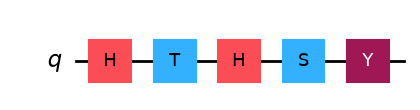

In [14]:
circuit = QuantumCircuit(1)
circuit.h(0)
circuit.t(0)
circuit.h(0)
circuit.s(0)
circuit.y(0)

display(circuit.draw(output="mpl"))

In [15]:
initial_state = Statevector([1,0])
final_state = initial_state.evolve(circuit)
display(final_state.draw("latex"))
print(final_state.data)

<IPython.core.display.Latex object>

[ 0.14644661-0.35355339j -0.35355339+0.85355339j]
